In [1]:

import pandas as pd
import matplotlib.pyplot as plt

rain = pd.read_csv("C:\\Users\\RUTHVIK REDDY\\lulc_project\\imd rainfall dataset 2004 to 2025\\IMD_Rainfall_Annual_Monsoon.csv")
temp = pd.read_csv("C:\\Users\\RUTHVIK REDDY\\lulc_project\\Temperature data ERA5 2004 to 2026\\ERA5_Temperature_2004_2025.csv")

print("Rainfall columns:", rain.columns.tolist())
print("Temperature columns:", temp.columns.tolist())

Rainfall columns: ['Year', 'Annual_Rainfall_mm', 'Monsoon_Rainfall_mm']
Temperature columns: ['Year', 'Annual_Mean_Temperature_C', 'Jan_Feb_Mean_Temperature_C']


Reference period: 2005–2025
Mean annual rainfall: 1153.88 mm
Mean monsoon rainfall: 988.18 mm
 Year  Annual_Rainfall_Anomaly_mm  Monsoon_Rainfall_Anomaly_mm
 2004                 -495.884870                  -533.562878
 2005                  254.210589                   148.226307
 2006                  252.063616                   169.220325
 2007                 -446.162275                  -357.363842
 2008                   28.378435                     8.398060
 2009                 -320.652021                  -367.146130
 2010                  431.738909                   379.988025
 2011                 -505.871381                  -377.073376
 2012                   -0.667951                    72.986194
 2013                  359.903948                   242.532703
 2014                 -349.607771                  -317.235302
 2015                 -270.843977                  -250.551525
 2016                  -30.721540                   -36.432446
 2017                 -4

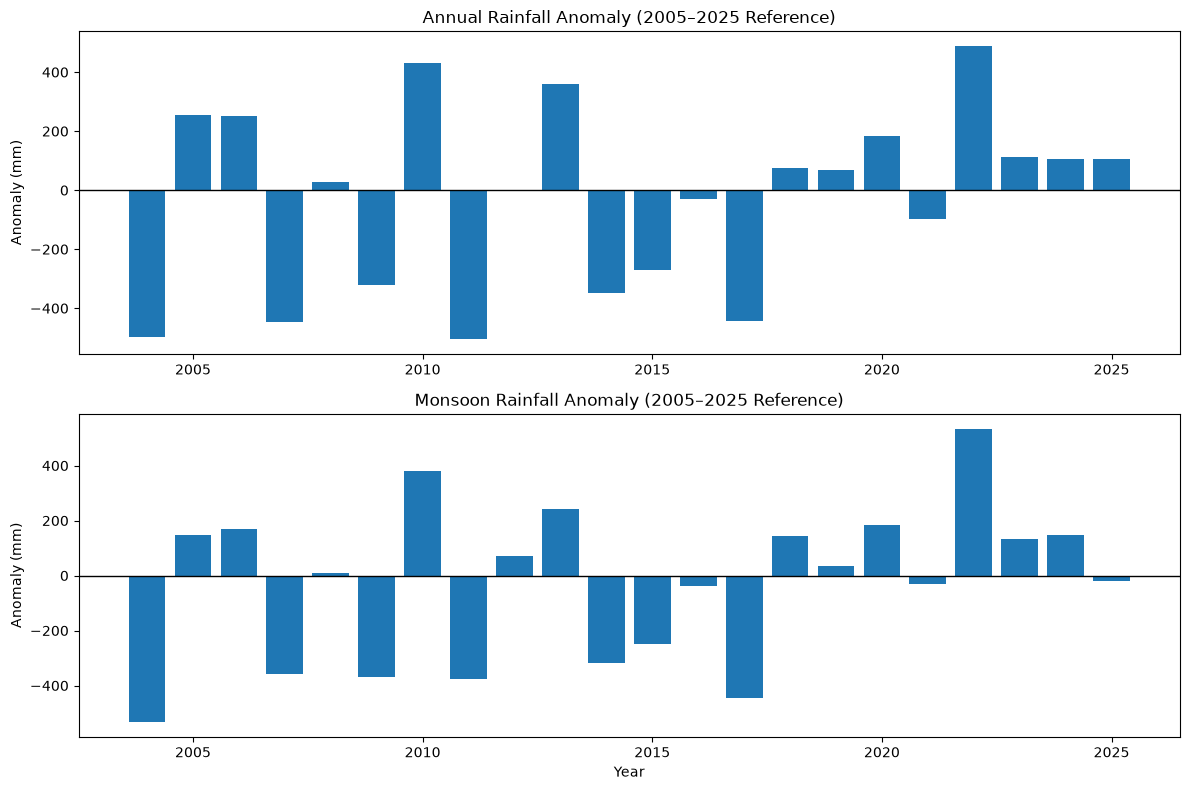

In [2]:

# Reference period
reference = rain[(rain["Year"] >= 2005) & (rain["Year"] <= 2025)]

# Calculate reference-period averages
annual_mean = reference["Annual_Rainfall_mm"].mean()
monsoon_mean = reference["Monsoon_Rainfall_mm"].mean()

# Calculate anomalies
rain["Annual_Rainfall_Anomaly_mm"] = (
    rain["Annual_Rainfall_mm"] - annual_mean
)

rain["Monsoon_Rainfall_Anomaly_mm"] = (
    rain["Monsoon_Rainfall_mm"] - monsoon_mean
)

# Save results
rain.to_csv("IMD_Rainfall_Anomalies.csv", index=False)

# Display results
print("Reference period: 2005–2025")
print(f"Mean annual rainfall: {annual_mean:.2f} mm")
print(f"Mean monsoon rainfall: {monsoon_mean:.2f} mm")

print(rain[[
    "Year",
    "Annual_Rainfall_Anomaly_mm",
    "Monsoon_Rainfall_Anomaly_mm"
]].to_string(index=False))

# Plot both anomalies
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].bar(
    rain["Year"], rain["Annual_Rainfall_Anomaly_mm"]
)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Annual Rainfall Anomaly (2005–2025 Reference)")
axes[0].set_ylabel("Anomaly (mm)")

axes[1].bar(
    rain["Year"], rain["Monsoon_Rainfall_Anomaly_mm"]
)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Monsoon Rainfall Anomaly (2005–2025 Reference)")
axes[1].set_ylabel("Anomaly (mm)")
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.show()


Reference annual temperature (°C): 27.58881161904762
Reference Jan–Feb temperature (°C): 24.43544304761905


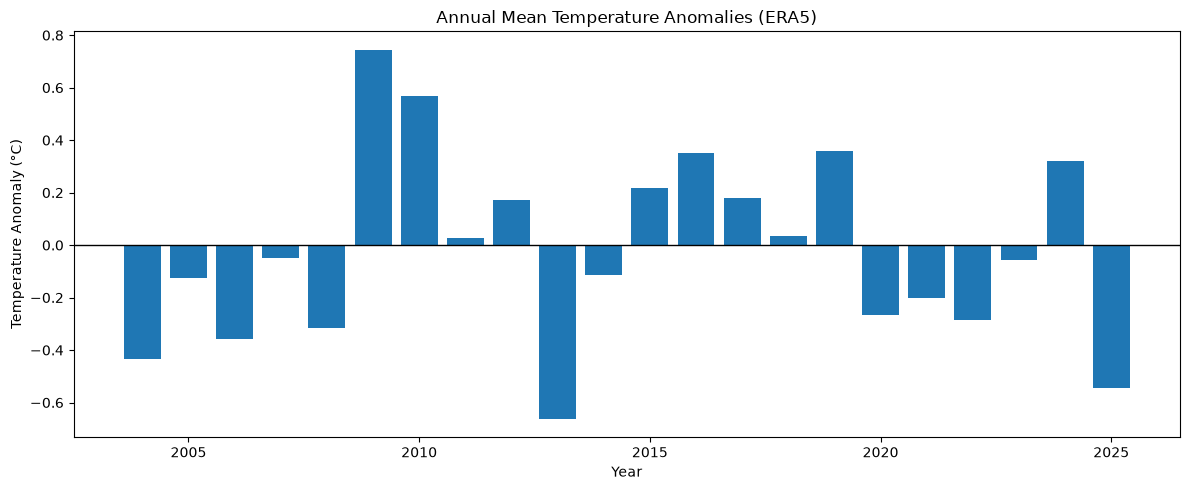

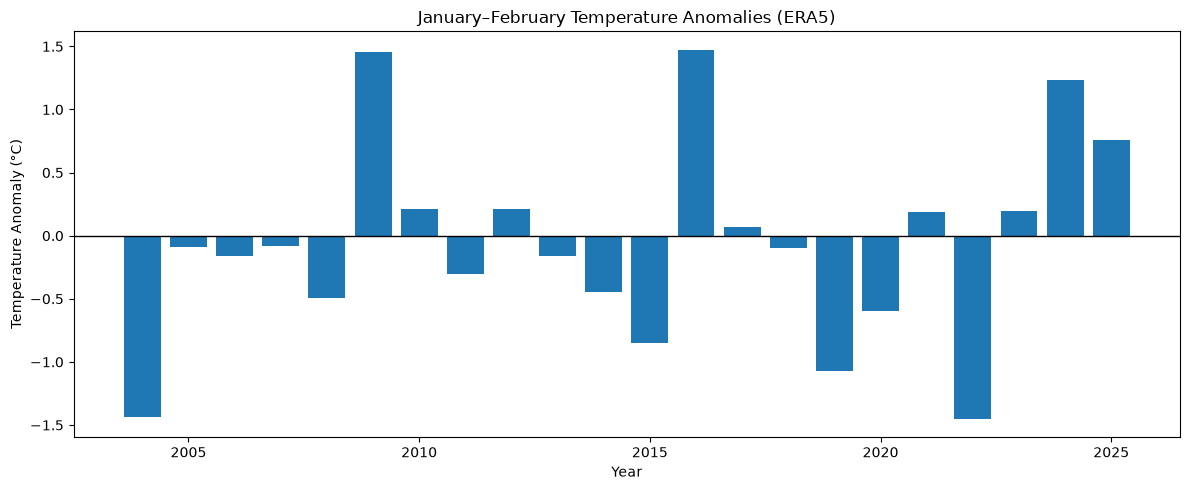

In [3]:
temp["Year"] = pd.to_numeric(temp["Year"], errors="coerce")
temp = temp.dropna(subset=["Year"]).copy()
temp["Year"] = temp["Year"].astype(int)

# Convert temperature columns to numeric
for col in [
    "Annual_Mean_Temperature_C",
    "Jan_Feb_Mean_Temperature_C"
]:
    temp[col] = pd.to_numeric(temp[col], errors="coerce")

# Reference period: 2005–2025
reference = temp["Year"].between(2005, 2025)

# Calculate annual temperature anomaly
annual_reference = temp.loc[
    reference, "Annual_Mean_Temperature_C"
].mean()

temp["Annual_Temperature_Anomaly_C"] = (
    temp["Annual_Mean_Temperature_C"] - annual_reference
)

# Calculate January–February temperature anomaly
jan_feb_reference = temp.loc[
    reference, "Jan_Feb_Mean_Temperature_C"
].mean()

temp["Jan_Feb_Temperature_Anomaly_C"] = (
    temp["Jan_Feb_Mean_Temperature_C"] - jan_feb_reference
)

print("Reference annual temperature (°C):", annual_reference)
print("Reference Jan–Feb temperature (°C):", jan_feb_reference)

# Save results
temp.to_csv("ERA5_Temperature_Anomalies.csv", index=False)

# Plot annual temperature anomalies
plt.figure(figsize=(12, 5))
plt.bar(temp["Year"], temp["Annual_Temperature_Anomaly_C"])
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (°C)")
plt.title("Annual Mean Temperature Anomalies (ERA5)")
plt.tight_layout()
plt.show()

# Plot January–February temperature anomalies
plt.figure(figsize=(12, 5))
plt.bar(temp["Year"], temp["Jan_Feb_Temperature_Anomaly_C"])
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Year")
plt.ylabel("Temperature Anomaly (°C)")
plt.title("January–February Temperature Anomalies (ERA5)")
plt.tight_layout()
plt.show()


Reference period: 2005–2025
Mean annual temperature: 27.59 °C
Mean Jan–Feb temperature: 24.44 °C
 Year  Annual_Temperature_Anomaly_C  Jan_Feb_Temperature_Anomaly_C
 2004                     -0.435814                      -1.436618
 2005                     -0.126839                      -0.087985
 2006                     -0.357899                      -0.163745
 2007                     -0.047398                      -0.082843
 2008                     -0.316979                      -0.495608
 2009                      0.744381                       1.455960
 2010                      0.567720                       0.211545
 2011                      0.028255                      -0.305347
 2012                      0.172708                       0.210935
 2013                     -0.660778                      -0.156893
 2014                     -0.112759                      -0.448718
 2015                      0.217697                      -0.849109
 2016                      0.350

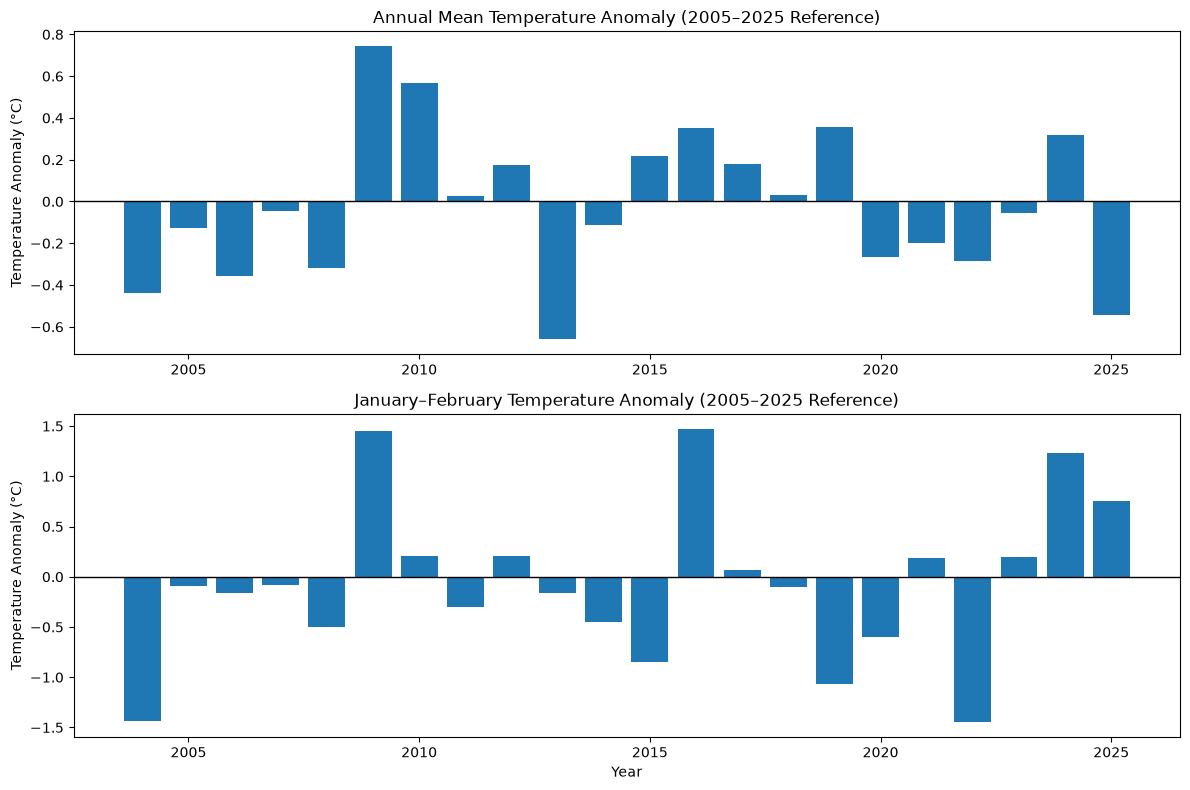

In [4]:
temp["Year"] = pd.to_numeric(temp["Year"], errors="coerce")
temp = temp.dropna(subset=["Year"]).copy()
temp["Year"] = temp["Year"].astype(int)

# Convert temperature columns to numeric
for col in [
    "Annual_Mean_Temperature_C",
    "Jan_Feb_Mean_Temperature_C"
]:
    temp[col] = pd.to_numeric(temp[col], errors="coerce")

# Reference period: 2005–2025
reference = temp["Year"].between(2005, 2025)

# Calculate annual temperature reference mean
annual_reference = temp.loc[
    reference, "Annual_Mean_Temperature_C"
].mean()

# Calculate annual temperature anomaly
temp["Annual_Temperature_Anomaly_C"] = (
    temp["Annual_Mean_Temperature_C"] - annual_reference
)

# Calculate January–February reference mean
jan_feb_reference = temp.loc[
    reference, "Jan_Feb_Mean_Temperature_C"
].mean()

# Calculate January–February temperature anomaly
temp["Jan_Feb_Temperature_Anomaly_C"] = (
    temp["Jan_Feb_Mean_Temperature_C"] - jan_feb_reference
)

# Print reference values
print("Reference period: 2005–2025")
print(f"Mean annual temperature: {annual_reference:.2f} °C")
print(f"Mean Jan–Feb temperature: {jan_feb_reference:.2f} °C")

# Save results
temp.to_csv("ERA5_Temperature_Anomalies.csv", index=False)

# Display anomalies
print(temp[[
    "Year",
    "Annual_Temperature_Anomaly_C",
    "Jan_Feb_Temperature_Anomaly_C"
]].to_string(index=False))


# ==========================================================
# Plot both temperature anomalies in the same image
# ==========================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Annual temperature anomaly
axes[0].bar(
    temp["Year"],
    temp["Annual_Temperature_Anomaly_C"]
)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title(
    "Annual Mean Temperature Anomaly (2005–2025 Reference)"
)
axes[0].set_ylabel("Temperature Anomaly (°C)")


# January–February temperature anomaly
axes[1].bar(
    temp["Year"],
    temp["Jan_Feb_Temperature_Anomaly_C"]
)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title(
    "January–February Temperature Anomaly (2005–2025 Reference)"
)
axes[1].set_ylabel("Temperature Anomaly (°C)")
axes[1].set_xlabel("Year")


plt.tight_layout()
plt.show()